# Gradient Boosting

This notebook evaluates baseline and tuned Gradient Boosting models for hotel
booking cancellation prediction. It uses the shared dataset split,
preprocessing pipeline, random state, cross-validation strategy, and
evaluation metrics.

Hyperparameter tuning uses training data and cross-validation only. Baseline
and tuned models are compared using their validation performance and
training-validation gaps before final test evaluation.

## 1. Load Shared Data Split

Load the selected feature dataset and reproduce the shared stratified
80/20 train/test split. Verify the partition sizes and target distributions
before defining the Gradient Boosting model.

In [1]:
from pathlib import Path
import sys

ROOT = next(
    path
    for path in [Path.cwd(), *Path.cwd().parents]
    if (path / "data/processed/hotel_booking_features.csv").is_file()
)

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import display

from scripts.model_evaluation_utils import (
    RANDOM_STATE,
    CV_SPLITS,
    load_feature_dataset,
    split_feature_dataset,
    class_distribution,
)

data = load_feature_dataset()
prepared = split_feature_dataset(data)

print(f"Random state: {RANDOM_STATE}")
print(f"CV folds: {CV_SPLITS}")
print(f"Training rows: {len(prepared.X_train):,}")
print(f"Test rows: {len(prepared.X_test):,}")
print(f"Predictors: {prepared.X_train.shape[1]}")

print("\nTraining class distribution")
display(class_distribution(prepared.y_train))

print("\nTest class distribution")
display(class_distribution(prepared.y_test))

Random state: 42
CV folds: 5
Training rows: 95,364
Test rows: 23,841
Predictors: 32

Training class distribution


,class,count,percent
0,0,60008,62.9252
1,1,35356,37.0748



Test class distribution


,class,count,percent
0,0,15002,62.9252
1,1,8839,37.0748


## 2. Baseline Gradient Boosting

Define a baseline Gradient Boosting classifier with 100 boosting stages,
a learning rate of 0.1, and a maximum tree depth of 3.

The classifier is combined with the shared preprocessing pipeline so that
preprocessing is learned separately within each cross-validation training
fold. This section defines the pipeline; fitting and evaluation follow
in the next section.

In [2]:
from sklearn.ensemble import GradientBoostingClassifier
from scripts.model_evaluation_utils import build_pipeline

baseline_model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=RANDOM_STATE,
)

baseline_pipeline = build_pipeline(
    baseline_model,
    prepared.X_train,
)

display(baseline_pipeline)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('model', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...), ...]"
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",1.0
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be exclude

## 3. Baseline Cross-Validation and Overfitting Check

Evaluate the baseline Gradient Boosting pipeline using the shared five-fold
stratified cross-validation strategy on training data only.

Report the mean and standard deviation of all common metrics. Compare
training scores with validation scores to assess generalization. A large
training-validation gap may indicate overfitting. The test partition is
not used in this section.

In [ ]:
from scripts.model_evaluation_utils import cross_validation_summary

baseline_cv = cross_validation_summary(
    "Gradient Boosting",
    "Baseline",
    baseline_pipeline,
    prepared.X_train,
    prepared.y_train,
)

print("Baseline cross-validation results:")
display(baseline_cv.round(4))

baseline_gap = baseline_cv.assign(
    train_cv_gap=baseline_cv["train_mean"] - baseline_cv["cv_mean"]
)

print("Training versus validation performance:")
display(
    baseline_gap[
        ["metric", "train_mean", "cv_mean", "train_cv_gap"]
    ].round(4)
)

Baseline cross-validation results:


,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Gradient Boosting,Baseline,accuracy,0.8515,0.0006,0.8504,0.0018
1,Gradient Boosting,Baseline,precision,0.8411,0.0022,0.8391,0.0053
2,Gradient Boosting,Baseline,recall,0.7392,0.0036,0.7381,0.0016
3,Gradient Boosting,Baseline,f1,0.7868,0.0013,0.7854,0.0019
4,Gradient Boosting,Baseline,roc_auc,0.9270,0.0003,0.9256,0.0010
5,Gradient Boosting,Baseline,pr_auc,0.8958,0.0007,0.8939,0.0015


Training versus validation performance:


,metric,train_mean,cv_mean,train_cv_gap
0,accuracy,0.8515,0.8504,0.0011
1,precision,0.8411,0.8391,0.0019
2,recall,0.7392,0.7381,0.0011
3,f1,0.7868,0.7854,0.0015
4,roc_auc,0.9270,0.9256,0.0015
5,pr_auc,0.8958,0.8939,0.0019


**Baseline interpretation:** Gradient Boosting achieved mean cross-validation
accuracy of 0.8504, precision of 0.8391, recall of 0.7381, and F1 of 0.7854.
Mean ROC-AUC was 0.9256, and average precision, stored as `pr_auc` in the
shared framework, was 0.8939.

The training-validation F1 gap was approximately 0.0015, providing little
evidence of substantial overfitting under this cross-validation setup.
Validation F1 also varied little across folds, with a standard deviation
of 0.0019.

Recall was lower than precision: the model detected approximately 73.81%
of actual cancellations across validation folds. Hyperparameter tuning will
investigate whether F1 and cancellation detection can improve while
maintaining generalization. The test set has not been used.

## 4. Gradient Boosting Hyperparameter Tuning

Use RandomizedSearchCV to investigate the number of boosting stages, learning
rate, tree depth, and minimum samples required for splits and leaves.

The search evaluates six parameter configurations using the shared five-fold
stratified cross-validation strategy on the full training partition.
F1 is the selection metric because it balances cancellation precision and
recall. All common metrics are recorded.

Preprocessing remains inside the pipeline and is fitted separately within
each training fold. The test set is not used for tuning.

In [6]:
from sklearn.model_selection import RandomizedSearchCV

from scripts.model_evaluation_utils import (
    COMMON_SCORING,
    get_cv,
)

search_pipeline = build_pipeline(
    GradientBoostingClassifier(random_state=RANDOM_STATE),
    prepared.X_train,
)

param_distributions = {
    "model__n_estimators": [100, 200],
    "model__learning_rate": [0.05, 0.1],
    "model__max_depth": [3, 5],
    "model__min_samples_split": [2, 20],
    "model__min_samples_leaf": [1, 10],
}

search = RandomizedSearchCV(
    estimator=search_pipeline,
    param_distributions=param_distributions,
    n_iter=6,
    scoring=COMMON_SCORING,
    refit="f1",
    cv=get_cv(),
    random_state=RANDOM_STATE,
    n_jobs=2,
    return_train_score=True,
    verbose=1,
    error_score="raise",
)

search.fit(prepared.X_train, prepared.y_train)

print("Best Gradient Boosting parameters:")
print(search.best_params_)
print(f"Best mean search CV F1: {search.best_score_:.4f}")

Fitting 5 folds for each of 6 candidates, totalling 30 fits
Best Gradient Boosting parameters:
{'model__n_estimators': 200, 'model__min_samples_split': 2, 'model__min_samples_leaf': 10, 'model__max_depth': 5, 'model__learning_rate': 0.1}
Best mean search CV F1: 0.8177


**Tuning result:** The best sampled configuration used 200 boosting stages,
a learning rate of 0.1, maximum tree depth of 5, minimum split size of 2,
and minimum leaf size of 10.

Its mean search CV F1 was 0.8177, compared with baseline CV F1 of 0.7854.
This is the best result among the six sampled configurations, not proof of
the globally optimal configuration. Because the same CV results were used
to select the parameters, this score may be optimistic.

## 5. Tuned Cross-Validation Results and Overfitting Check

Extract all common metrics for the selected configuration from the completed
hyperparameter search. These results use the shared five-fold CV strategy
on the full training partition.

Compare training and validation means to assess the generalization gap.
These are tuning CV results rather than an independent evaluation.

In [7]:
tuned_pipeline = search.best_estimator_
best_index = search.best_index_
search_results = search.cv_results_

tuned_cv = pd.DataFrame([
    {
        "model": "Gradient Boosting",
        "version": "Tuned",
        "metric": metric,
        "train_mean": search_results[f"mean_train_{metric}"][best_index],
        "train_std": search_results[f"std_train_{metric}"][best_index],
        "cv_mean": search_results[f"mean_test_{metric}"][best_index],
        "cv_std": search_results[f"std_test_{metric}"][best_index],
    }
    for metric in COMMON_SCORING
])

display(tuned_cv.round(4))

tuned_gap = tuned_cv.assign(
    train_cv_gap=tuned_cv["train_mean"] - tuned_cv["cv_mean"]
)

display(
    tuned_gap[
        ["metric", "train_mean", "cv_mean", "train_cv_gap"]
    ].round(4)
)

,model,version,metric,train_mean,train_std,cv_mean,cv_std
0,Gradient Boosting,Tuned,accuracy,0.8769,0.0003,0.8688,0.0013
1,Gradient Boosting,Tuned,precision,0.8541,0.0009,0.8435,0.0043
2,Gradient Boosting,Tuned,recall,0.8054,0.0014,0.7934,0.0038
3,Gradient Boosting,Tuned,f1,0.8291,0.0005,0.8177,0.0016
4,Gradient Boosting,Tuned,roc_auc,0.9520,0.0003,0.9440,0.0010
5,Gradient Boosting,Tuned,pr_auc,0.9289,0.0004,0.9181,0.0013


,metric,train_mean,cv_mean,train_cv_gap
0,accuracy,0.8769,0.8688,0.0080
1,precision,0.8541,0.8435,0.0107
2,recall,0.8054,0.7934,0.0120
3,f1,0.8291,0.8177,0.0114
4,roc_auc,0.9520,0.9440,0.0080
5,pr_auc,0.9289,0.9181,0.0108


**Tuned interpretation:** Mean validation F1 increased from 0.7854 to 0.8177,
and recall increased from 0.7381 to 0.7934. Accuracy, precision, ROC-AUC,
and average precision also improved.

The training-validation F1 gap increased from approximately 0.0015 to
0.0114. This suggests increased fitting to the training folds, although
validation performance improved. Tuning therefore improved the measured
CV performance but did not reduce the generalization gap.

These scores come from the CV search used to select the configuration;
they are not independent estimates of the tuning procedure's performance.

## 6. Baseline versus Tuned Cross-Validation Comparison

Compare validation metrics for the baseline and selected configuration
before final test evaluation. Report both performance changes and the
training-validation F1 gap.

In [8]:
cv_comparison = pd.concat(
    [baseline_cv, tuned_cv],
    ignore_index=True
)

cv_metric_comparison = cv_comparison.pivot(
    index="metric",
    columns="version",
    values="cv_mean"
).reindex(list(COMMON_SCORING))

cv_metric_comparison["change"] = (
    cv_metric_comparison["Tuned"] - cv_metric_comparison["Baseline"]
)

display(cv_metric_comparison.round(4))

f1_gap_comparison = cv_comparison.loc[
    cv_comparison["metric"] == "f1",
    ["version", "train_mean", "cv_mean"]
].copy()

f1_gap_comparison["train_cv_gap"] = (
    f1_gap_comparison["train_mean"] - f1_gap_comparison["cv_mean"]
)

display(f1_gap_comparison.round(4))

version,Baseline,Tuned,change
metric,,,
accuracy,0.8504,0.8688,0.0184
precision,0.8391,0.8435,0.0043
recall,0.7381,0.7934,0.0553
f1,0.7854,0.8177,0.0323
roc_auc,0.9256,0.9440,0.0185
pr_auc,0.8939,0.9181,0.0242


,version,train_mean,cv_mean,train_cv_gap
3,Baseline,0.7868,0.7854,0.0015
9,Tuned,0.8291,0.8177,0.0114


## 7. Final Test Evaluation

Fit the finalized baseline and tuned pipelines on the full training partition
and report the common test metrics. Test results are used for reporting,
not further hyperparameter tuning.

In [9]:
from scripts.model_evaluation_utils import fit_and_evaluate

baseline_pipeline, baseline_test = fit_and_evaluate(
    "Gradient Boosting", "Baseline", baseline_pipeline, prepared
)

tuned_pipeline, tuned_test = fit_and_evaluate(
    "Gradient Boosting", "Tuned", tuned_pipeline, prepared
)

test_comparison = pd.DataFrame([baseline_test, tuned_test])
display(test_comparison.round(4))

,model,version,accuracy,precision,recall,f1,roc_auc,pr_auc,fit_seconds
0,Gradient Boosting,Baseline,0.8524,0.8428,0.7398,0.7879,0.9250,0.8938,13.9322
1,Gradient Boosting,Tuned,0.8691,0.8450,0.7923,0.8178,0.9446,0.9184,62.1298


## 8. Confusion Matrices

Compare correct predictions, missed cancellations, and false cancellation
alerts for the baseline and tuned models.

In [10]:
from scripts.model_evaluation_utils import confusion_matrix_frame

baseline_confusion = confusion_matrix_frame(
    prepared.y_test,
    baseline_pipeline.predict(prepared.X_test)
)

tuned_confusion = confusion_matrix_frame(
    prepared.y_test,
    tuned_pipeline.predict(prepared.X_test)
)

print("Baseline confusion matrix:")
display(baseline_confusion)

print("Tuned confusion matrix:")
display(tuned_confusion)

Baseline confusion matrix:


,Predicted 0,Predicted 1
Actual 0,13782,1220
Actual 1,2300,6539


Tuned confusion matrix:


,Predicted 0,Predicted 1
Actual 0,13717,1285
Actual 1,1836,7003


## 9. ROC and Precision-Recall Curves

Visualize the baseline and tuned models across decision thresholds.
These curves are reported without changing the prediction threshold.


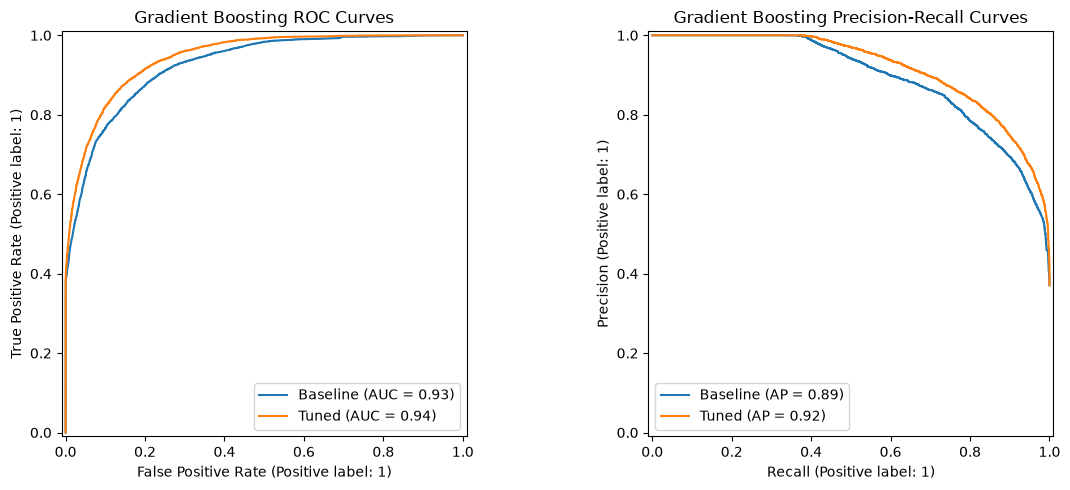

In [11]:
import matplotlib.pyplot as plt
from sklearn.metrics import RocCurveDisplay, PrecisionRecallDisplay
from scripts.model_evaluation_utils import OUTPUT_DIR

FIGURE_DIR = OUTPUT_DIR / "Figures"
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for label, pipeline in [
    ("Baseline", baseline_pipeline),
    ("Tuned", tuned_pipeline),
]:
    RocCurveDisplay.from_estimator(
        pipeline, prepared.X_test, prepared.y_test,
        name=label, ax=axes[0]
    )
    PrecisionRecallDisplay.from_estimator(
        pipeline, prepared.X_test, prepared.y_test,
        name=label, ax=axes[1]
    )

axes[0].set_title("Gradient Boosting ROC Curves")
axes[1].set_title("Gradient Boosting Precision-Recall Curves")
plt.tight_layout()
plt.savefig(
    FIGURE_DIR / "gradient_boosting_curves.png",
    dpi=300, bbox_inches="tight"
)
plt.show()

## 10. Save Results

Export baseline and tuned CV metrics, test metrics, confusion matrices,
and selected hyperparameters for reproducible comparison.

In [12]:
import json
from scripts.model_evaluation_utils import save_results

save_results(cv_comparison, "gradient_boosting_cv_results.csv")
save_results(test_comparison, "gradient_boosting_test_results.csv")

save_results(
    baseline_confusion.rename_axis("actual_class").reset_index(),
    "gradient_boosting_baseline_confusion_matrix.csv"
)
save_results(
    tuned_confusion.rename_axis("actual_class").reset_index(),
    "gradient_boosting_tuned_confusion_matrix.csv"
)

parameter_path = OUTPUT_DIR / "gradient_boosting_best_params.json"
parameter_path.write_text(
    json.dumps(search.best_params_, indent=2),
    encoding="utf-8"
)

print("Gradient Boosting results saved under 06_Model_Evaluation.")

Gradient Boosting results saved under 06_Model_Evaluation.


## 11. Conclusion

Tuning improved mean CV F1 from 0.7854 to 0.8177 and test F1 from 0.7879
to 0.8178. Test recall increased from 0.7398 to 0.7923, detecting 464 more
cancellations with 65 additional false alerts.

The training-validation F1 gap increased from approximately 0.0015 to
0.0114. Tuning improved measured performance but did not reduce the
generalization gap. Tuned CV results reflect parameter selection using
the same folds.

The selected configuration used 200 boosting stages, learning rate 0.1,
maximum depth 5, minimum split size 2, and minimum leaf size 10.
Preprocessing and tuning used training data only.

The saved results will contribute to the overall model comparison.
Final model selection will consider CV performance and the group's
operational requirements.